# Monthly composites from Sentinel-2 and Landsat

**Question:** *How do we turn hundreds of partly cloudy satellite scenes into one clean, comparable image
per month?*

Drought develops over weeks to months, while individual scenes are irregular: clouds, shadows, haze and
gaps differ from one overpass to the next. A **monthly median composite** fixes that. Clouds are masked in
every scene, then the median of all clear observations in a month is taken pixel by pixel. The result is a
regular time axis (one image per month) on which drought indicators can be computed.

The case study is a block of fields around Lassee and Obersiebenbrunn in the **Marchfeld**, Lower Austria:
Austria's main arable plain, roughly 500–550 mm of rain a year, and a patchwork of rainfed and
groundwater-irrigated fields.

| | Sentinel-2 L2A | Landsat 8/9 Collection 2 L2 |
|---|---|---|
| Pixel size | 10–20 m (we use 20 m) | 30 m optical, thermal 100 m resampled to 30 m |
| Revisit | 5 days (2 satellites) | 8 days (2 satellites) |
| Record | 2015– (both satellites from 2017) | 2013– (Landsat 8), 2021– (Landsat 9) |
| Cloud mask | Scene Classification Layer (SCL) | QA_PIXEL bit flags |
| Extra | red-edge bands | land-surface temperature (LST) |

Data come from Microsoft Planetary Computer through STAC: free, no account, and only the pixels of the
area of interest are read.

In [1]:
import sys
import warnings
from pathlib import Path

# make the course helper package importable from any sub-folder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "droughtkit").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import droughtkit as dk
from droughtkit import plotting as dkp

dkp.use_style()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.float_format", "{:.2f}".format)

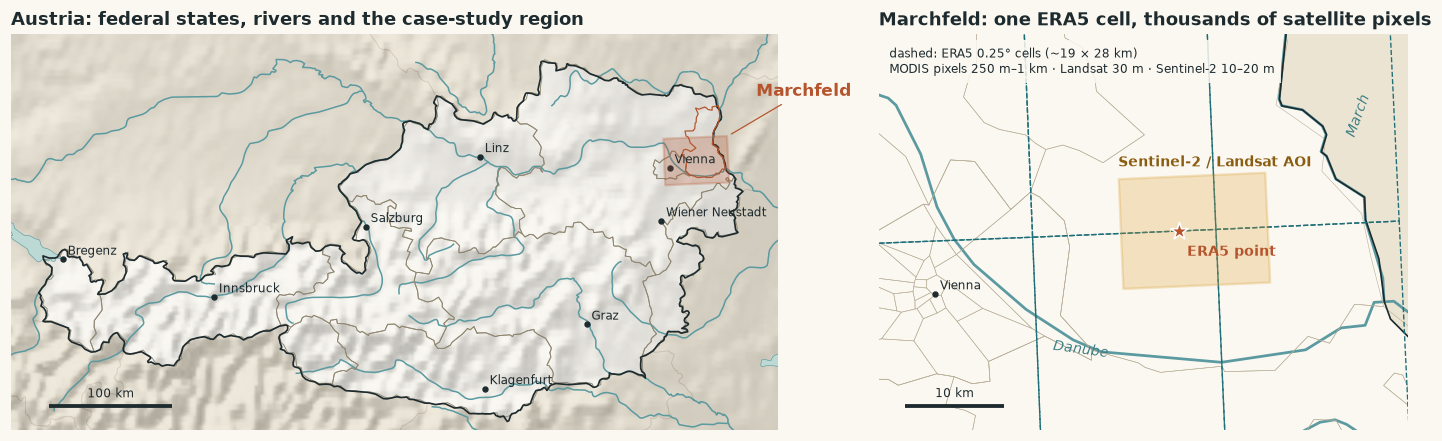

In [2]:
from droughtkit import maps as dkm
from droughtkit import remote_sensing as rs
from droughtkit import sample as sm

BBOX = dk.MARCHFELD["bbox"]            # lon/lat: ~15 x 11 km of fields near Lassee
YEARS = range(2017, 2027)             # 2017-2025 serve as the reference years, 2026 is the drought year
MONTHS = range(4, 10)                 # April-September growing season
RUN_STAC = True                       # False = use the offline synthetic stand-ins

fig = dkm.study_area_map()

In [3]:
try:
    if not RUN_STAC:
        raise RuntimeError("RUN_STAC is False")
    catalog = rs.open_catalog()
    rs.search("sentinel-2-l2a", BBOX, "2026-07-01", "2026-07-31", catalog=catalog)
    ONLINE = True
    print("Planetary Computer reachable: using real Sentinel-2 and Landsat data.")
except Exception as exc:
    ONLINE, catalog = False, None
    print(f"Planetary Computer not reachable ({type(exc).__name__}). "
          "Using the offline synthetic stand-ins; every figure is labelled.")

Planetary Computer reachable: using real Sentinel-2 and Landsat data.


> **Which data are you looking at?** With internet access the cells below read real Sentinel-2 and Landsat
> scenes. Offline they use `droughtkit.sample`, a synthetic Marchfeld-like block of fields (winter wheat,
> maize, sugar beet, irrigated vegetables, grassland, a riparian forest strip and a village) whose rainfed
> crops respond to drought and irrigated crops barely do. The outputs stored in this notebook come from
> the offline run.

## From scenes to a composite: one month, step by step

We take every Sentinel-2 acquisition of July 2026, look at what the clouds do, apply the SCL mask, and take
the median. The SCL classes kept as clear are vegetation (4), bare soil (5) and water (6); everything else
(cloud, cirrus, shadow, snow, saturated, unclassified) is removed.

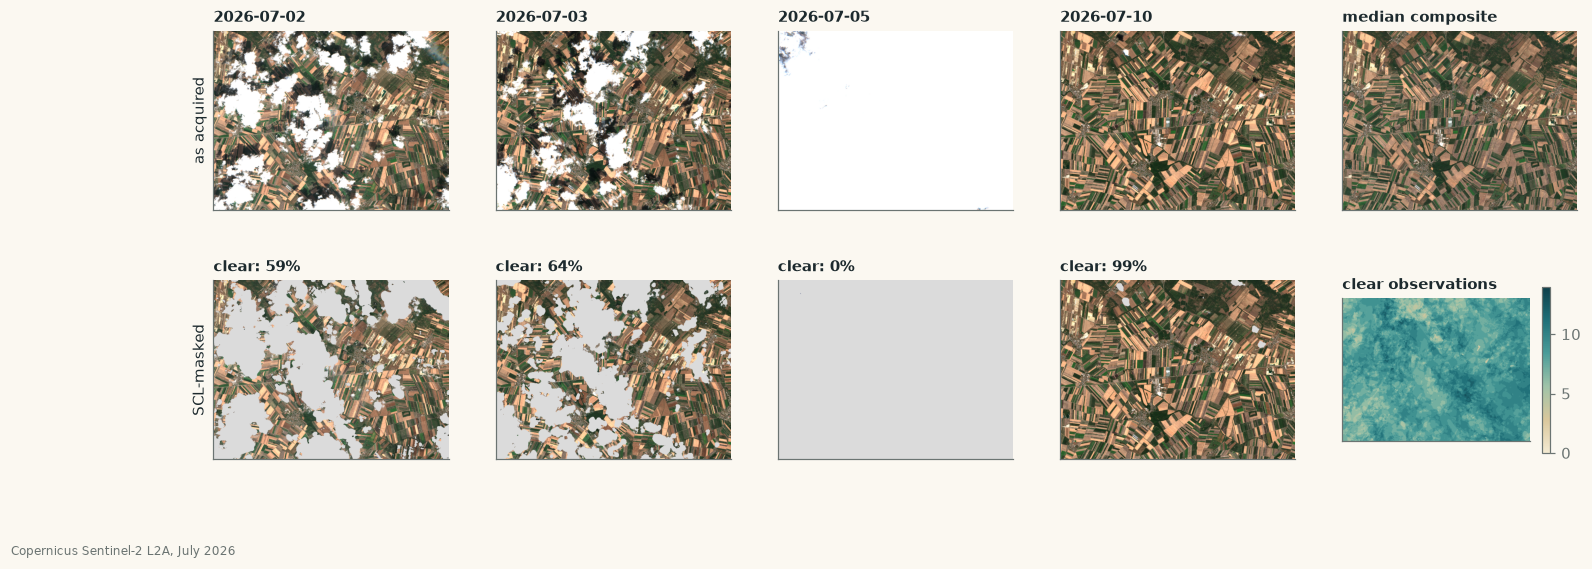

In [4]:
if ONLINE:
    from odc.stac import load
    items = rs.search("sentinel-2-l2a", BBOX, "2026-07-01", "2026-07-31",
                      {"eo:cloud_cover": {"lt": 80}}, catalog)
    raw = load(items, bands=[*rs.S2_BANDS, "SCL"], bbox=BBOX, resolution=20,
               crs=f"EPSG:{rs.utm_epsg(BBOX)}", groupby="solar_day").compute()
    scenes = (raw[list(rs.S2_BANDS)] / 10_000).rename(rs.S2_BANDS)
    scenes = scenes - 0.1          # processing baseline >= 04.00: remove the +1000 offset
    scenes["SCL"] = raw.SCL
    SRC = "Copernicus Sentinel-2 L2A, July 2026"
else:
    scenes = sm.sample_scenes(2026, 7)
    SRC = scenes.attrs["source"]

clear = scenes.SCL.isin(rs.S2_CLEAR)
masked = scenes[rs.COMMON].where(clear)
july = rs.monthly_composite(masked).isel(time=0)

n = min(scenes.sizes["time"], 4)
fig, ax = plt.subplots(2, n + 1, figsize=(3.2 * (n + 1), 5.4))
for i in range(n):
    ax[0, i].imshow(rs.rgb(scenes.isel(time=i)))
    ax[0, i].set_title(str(scenes.time.values[i])[:10], fontsize=10)
    ax[1, i].imshow(rs.rgb(masked.isel(time=i)))
    ax[1, i].set_title(f"clear: {float(clear.isel(time=i).mean()):.0%}", fontsize=10)
ax[0, n].imshow(rs.rgb(july)); ax[0, n].set_title("median composite", fontsize=10, fontweight="bold")
m = ax[1, n].imshow(july.n_obs, cmap=dkp.SAND_TEAL, vmin=0, vmax=scenes.sizes["time"])
ax[1, n].set_title("clear observations", fontsize=10)
plt.colorbar(m, ax=ax[1, n], shrink=0.8)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
ax[0, 0].set_ylabel("as acquired"); ax[1, 0].set_ylabel("SCL-masked")
dkp.source_note(fig, SRC)

Three things to notice:

* **The median removes what the mask misses.** Thin cloud edges and haze that slip through the SCL are
  outliers among several clear looks and drop out of the median.
* **Coverage is uneven.** Some pixels had many clear looks, some one, a few none. Months with no clear
  observation stay empty: never fill them silently.
* **Masking comes first.** A median of unmasked scenes can still be bright where clouds sat repeatedly.

## A multi-year monthly cube

`rs.monthly_cube` repeats this for every month and year, one year at a time, and caches each year as
NetCDF in `data/composites/`. It also applies two corrections that are easy to forget:

* **Sentinel-2 harmonisation.** Since processing baseline 04.00 (25 January 2022) L2A values carry a +1000
  offset. `rs.load_sentinel2` removes it per acquisition using the `s2:processing_baseline` property.
  Without that, every image after 2022 looks brighter and the 2026 drought would be partly hidden.
* **Landsat scaling.** Collection 2 reflectance is `DN × 0.0000275 − 0.2`; surface temperature is
  `DN × 0.00341802 + 149` kelvin.

The first online run reads several hundred scenes and takes a while (roughly 10–30 minutes, depending on
connection). Re-runs read the cache.

In [5]:
if ONLINE:
    s2 = rs.monthly_cube("sentinel2", BBOX, YEARS, MONTHS, cache_dir=ROOT / "data" / "composites",
                         catalog=catalog, max_cloud=70)
    ls = rs.monthly_cube("landsat", BBOX, range(2017, 2027), MONTHS,
                         cache_dir=ROOT / "data" / "composites", catalog=catalog, max_cloud=70)
else:
    s2 = sm.sample_composites(YEARS, MONTHS)
    ls = sm.sample_landsat(s2)
print(s2.attrs["source"])
s2

sentinel2 2017: 6 monthly composites
sentinel2 2018: 6 monthly composites
sentinel2 2019: 6 monthly composites
sentinel2 2020: 6 monthly composites
sentinel2 2021: 6 monthly composites
sentinel2 2022: 6 monthly composites
sentinel2 2023: 6 monthly composites
sentinel2 2024: 6 monthly composites
sentinel2 2025: 6 monthly composites
sentinel2 2026: 6 monthly composites
landsat 2017: 6 monthly composites
landsat 2018: 6 monthly composites
landsat 2019: 6 monthly composites
landsat 2020: 6 monthly composites
landsat 2021: 6 monthly composites
landsat 2022: 6 monthly composites
landsat 2023: 6 monthly composites
landsat 2024: 6 monthly composites
landsat 2025: 6 monthly composites
landsat 2026: 6 monthly composites
Copernicus Sentinel-2 L2A via Microsoft Planetary Computer, monthly median composites


<xarray.Dataset> Size: 1GB
Dimensions:  (time: 60, y: 574, x: 755)
Coordinates:
  * time     (time) datetime64[us] 480B 2017-04-01 2017-05-01 ... 2026-09-01
  * y        (y) float64 5kB 5.351e+06 5.351e+06 5.351e+06 ... 5.34e+06 5.34e+06
  * x        (x) float64 6kB 6.202e+05 6.202e+05 ... 6.352e+05 6.352e+05
Data variables:
    blue     (time, y, x) float64 208MB 0.05845 0.0582 0.0445 ... 0.0425 0.0346
    green    (time, y, x) float64 208MB 0.0775 0.0752 0.0616 ... 0.0795 0.0689
    red      (time, y, x) float64 208MB 0.1046 0.1016 0.0877 ... 0.0447 0.0401
    nir      (time, y, x) float64 208MB 0.151 0.1501 0.1271 ... 0.358 0.2637
    swir1    (time, y, x) float64 208MB 0.2166 0.2092 0.214 ... 0.2038 0.1711
    swir2    (time, y, x) float64 208MB 0.2096 0.1948 0.2037 ... 0.1166 0.0917
    n_obs    (time, y, x) int16 52MB 2 2 1 1 1 1 1 1 1 1 ... 9 9 9 9 9 9 9 9 9 9
Attributes:
    sensor:   Sentinel-2 L2A
    source:   Copernicus Sentinel-2 L2A via Microsoft Planetary Computer, mon...

### How well is each month observed?

Before computing any indicator, check coverage. The table shows the share of the AOI with at least one
clear observation and the median number of clear looks per pixel.

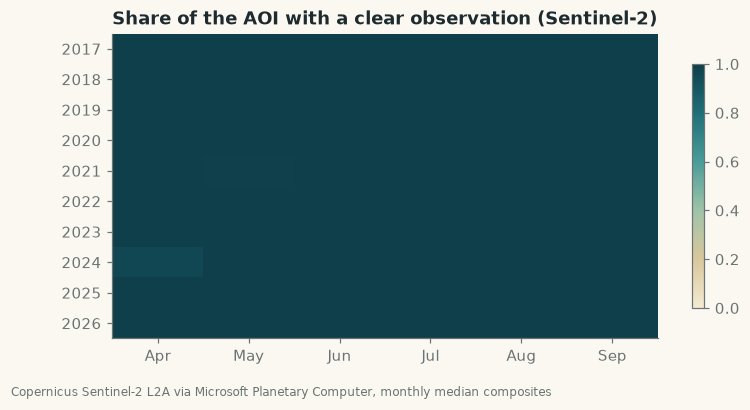

In [6]:
first = rs.COMMON[2]          # red band as reference
cov = pd.DataFrame({
    "valid share": s2[first].notnull().mean(["x", "y"]).to_series(),
    "median clear looks": s2.n_obs.median(["x", "y"]).to_series(),
})
table = cov["valid share"].groupby([cov.index.year, cov.index.month]).first().unstack()
table.index.name, table.columns.name = "year", "month"

fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(table.to_numpy(), cmap=dkp.SAND_TEAL, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(table.shape[1]), [pd.Timestamp(2000, m, 1).strftime("%b") for m in table.columns])
ax.set_yticks(range(table.shape[0]), table.index); ax.grid(False)
ax.set_title("Share of the AOI with a clear observation (Sentinel-2)")
plt.colorbar(im, ax=ax, shrink=0.8)
dkp.source_note(fig, s2.attrs["source"])

### The same place, month by month

True-colour composites for the 2026 season. Grey pixels had no clear observation that month. Watch the winter-cereal fields turn golden and get harvested in
June–July while maize and sugar beet green up, and the irrigated fields that stay green through the summer.

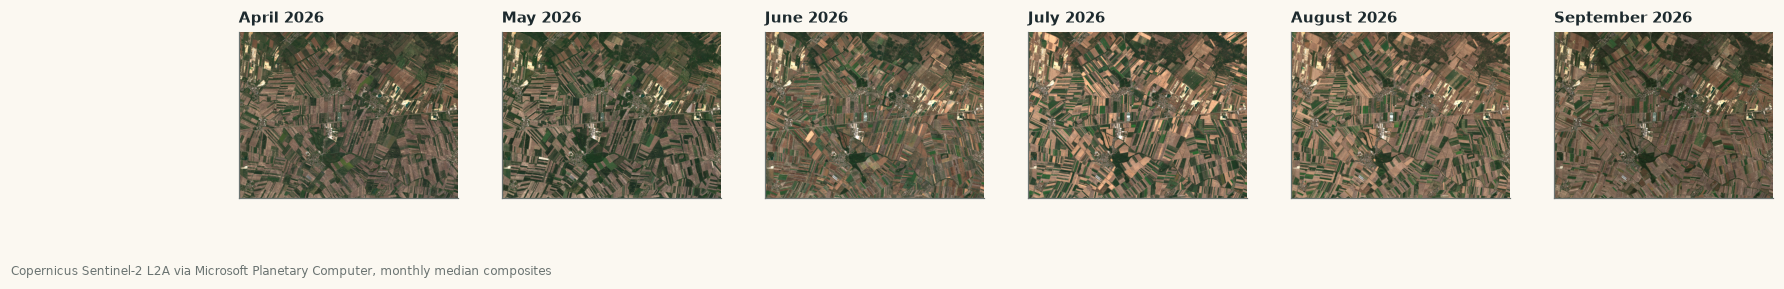

In [7]:
year = s2.sel(time=s2.time.dt.year == 2026)
fig, ax = plt.subplots(1, year.sizes["time"], figsize=(3 * year.sizes["time"], 2.7))
for a, t in zip(np.atleast_1d(ax), year.time.values):
    a.imshow(rs.rgb(year.sel(time=t)))
    a.set_title(pd.Timestamp(t).strftime("%B %Y"), fontsize=10)
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
dkp.source_note(fig, s2.attrs["source"])

### Sentinel-2 and Landsat side by side

Landsat has coarser pixels but adds the thermal band. After band renaming and scaling, the two sensors give
very similar NDVI for the same month. Small systematic differences remain (spectral response, view
geometry, pixel size); NASA's Harmonized Landsat Sentinel-2 product (HLS) corrects them formally.

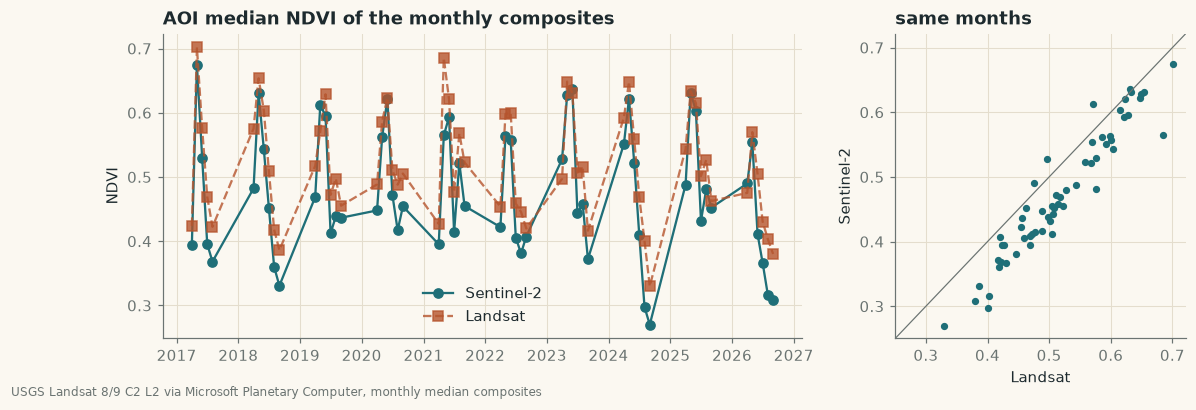

In [8]:
nd_s2 = dk.spectral_indices(s2).NDVI
nd_ls = (ls.nir - ls.red) / (ls.nir + ls.red)
both = pd.DataFrame({"Sentinel-2": rs.aoi_median(nd_s2), "Landsat": rs.aoi_median(nd_ls)}).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(both.index, both["Sentinel-2"], "o-", color=dkp.WET, label="Sentinel-2")
ax[0].plot(both.index, both["Landsat"], "s--", color=dkp.DRY, label="Landsat", alpha=0.8)
ax[0].set(title="AOI median NDVI of the monthly composites", ylabel="NDVI"); ax[0].legend()
ax[1].scatter(both["Landsat"], both["Sentinel-2"], s=14, color=dkp.WET)
lims = [both.min().min() - 0.02, both.max().max() + 0.02]
ax[1].plot(lims, lims, color=dkp.MUTED, lw=0.8); ax[1].set(xlim=lims, ylim=lims,
          xlabel="Landsat", ylabel="Sentinel-2", title="same months")
dkp.source_note(fig, ls.attrs["source"])

In [9]:
out = ROOT / "data"
out.mkdir(exist_ok=True)
s2.to_netcdf(out / "s2_marchfeld_monthly.nc")
ls.to_netcdf(out / "landsat_marchfeld_monthly.nc")
print("saved monthly composites to data/ for notebook 2")

saved monthly composites to data/ for notebook 2


## Exercises

1. **Cloud threshold.** Rebuild July 2026 with `max_cloud=30` and `max_cloud=90`. How do coverage and the
   composite change? Why can a generous scene-level threshold be better when a pixel mask is applied?
2. **Mask choice.** Add SCL class 7 (unclassified) to the clear classes. Where does the composite change?
3. **Harmonisation.** Build a 2021 and a 2023 July composite without removing the +1000 offset. How large is
   the apparent NDVI change that is pure processing artefact?
4. **Mean vs median.** Replace the median by the mean in `rs.monthly_composite`. Which pixels change most?
5. **Your own AOI.** Move `BBOX` to another Austrian farming area (e.g. the Weinviertel, the Parndorfer
   Platte or the Tullnerfeld) and inspect coverage over the season.